# 第05章 寻优的旅程：A组实验

> 本章整合非线性方程与数值优化内容。本实验使用纯 NumPy 从底层手搓核心算法，验证理论课上的收敛阶、下降条件与信赖域思想。

**四个核心概念：** 非线性迭代、下降方向与步长、Newton型方法、非线性最小二乘。

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# 设置 Jupyter 中的中文字体，防止画图时中文乱码
plt.rcParams['font.sans-serif'] = ['SimHei']  # Windows系统用黑体
plt.rcParams['axes.unicode_minus'] = False

## 5.1 非线性方程：从夹逼到迭代

**先写预测：** 
1. 二分法一定能收敛，但速度最慢。
2. 不动点迭代的速度取决于根附近的  $|g'(x^{\ast})|$  ，这里构造的  $g(x)=x/2+1/x$  收敛会非常快。
3. 经典的 Newton 法虽然局部二次收敛，但如果初值选得不好，比如解  $x^3-2x+2=0$  从 0 出发，可能会陷入死循环。

**完整实验任务：** 
以  $x^2-2=0$  为主例，对比二分法、不动点迭代和Newton法。补充  $x^3-2x+2$  从 0 出发的Newton二周期现象。

In [7]:
# 1. 二分法
def bisection(f, a, b, tol=1e-10, maxit=100):
    fa, fb = f(a), f(b)
    if fa * fb >= 0: raise ValueError("必须异号")
    for k in range(maxit):
        m = (a + b) / 2
        if f(m) == 0 or (b - a) / 2 < tol: return m, k+1
        if fa * f(m) < 0: b = m
        else: a, fa = m, f(m)
    return (a+b)/2, maxit

# 2. 不动点迭代
def fixed_point(g, x0, tol=1e-10, maxit=100):
    x = x0
    for k in range(maxit):
        x_new = g(x)
        if abs(x_new - x) < tol: return x_new, k+1
        x = x_new
    return x, maxit

# 3. Newton 法
def newton(f, df, x0, tol=1e-10, maxit=100):
    x = x0
    for k in range(maxit):
        fx = f(x)
        if abs(fx) < tol: return x, k+1
        x = x - fx / df(x)
    return x, maxit

# === 任务 A：x^2 - 2 = 0 ===
f = lambda x: x**2 - 2
df = lambda x: 2*x
g = lambda x: x/2 + 1/x

root_b, iter_b = bisection(f, 1, 2)
root_f, iter_f = fixed_point(g, 1.0)
root_n, iter_n = newton(f, df, 1.0)

print("=== 实验 1：x^2 - 2 = 0 ===")
print(f"二分法  : 根={root_b:.10f}, 迭代={iter_b}次")
print(f"不动点法: 根={root_f:.10f}, 迭代={iter_f}次")
print(f"Newton  : 根={root_n:.10f}, 迭代={iter_n}次")

# === 任务 B：x^3 - 2x + 2 = 0 的二周期现象 ===
print("\n=== 实验 2：x^3 - 2x + 2 = 0, 从 x0=0 出发 ===")
f2 = lambda x: x**3 - 2*x + 2
df2 = lambda x: 3*x**2 - 2
x = 0.0
for k in range(6):
    print(f"k={k}, x={x:.6f}, f(x)={f2(x):.6f}")
    x = x - f2(x) / df2(x)

=== 实验 1：x^2 - 2 = 0 ===
二分法  : 根=1.4142135623, 迭代=34次
不动点法: 根=1.4142135624, 迭代=5次
Newton  : 根=1.4142135624, 迭代=5次

=== 实验 2：x^3 - 2x + 2 = 0, 从 x0=0 出发 ===
k=0, x=0.000000, f(x)=2.000000
k=1, x=1.000000, f(x)=1.000000
k=2, x=0.000000, f(x)=2.000000
k=3, x=1.000000, f(x)=1.000000
k=4, x=0.000000, f(x)=2.000000
k=5, x=1.000000, f(x)=1.000000


**本组实现与实际结果：**
- 对于  $x^2-2=0$  ，Newton 法仅需 5 步达到机器精度，不动点迭代 5 步，二分法需 34 步。
- 对于  $x^3-2x+2=0$  ，从  $x_0=0$  出发，算出来  $x_1=1$  ， $x_2=0$  ， $x_3=1$  …… 完全陷入了 0 和 1 之间的**二周期死循环**。

**风险核验：** 
1. 残差小不必意味着根误差小。
2. Newton 从任意初值收敛是不成立的（实验 2 完美证明了这一点，必须受限于初值和函数的局部曲率）。

## 5.2 下降方向：往哪里走，走多远

**先写预测：** 
对于病态矩阵（条件数大），固定步长太大会导致目标函数振荡发散；Armijo 回溯线搜索能在远处自动缩小步长，保证每一步目标函数都充分下降。

**完整实验任务：** 
对  $\phi(x,y) = (x^2+20y^2)/2$  比较不同固定步长与回溯，画出函数值曲线。

E:\ANACONDA\lib\site-packages\matplotlib\mathtext.py:849: MathTextWarning: Font 'default' does not have a glyph for '-' [U+2212]
  MathTextWarning)
E:\ANACONDA\lib\site-packages\matplotlib\mathtext.py:850: MathTextWarning: Substituting with a dummy symbol.
  warn("Substituting with a dummy symbol.", MathTextWarning)


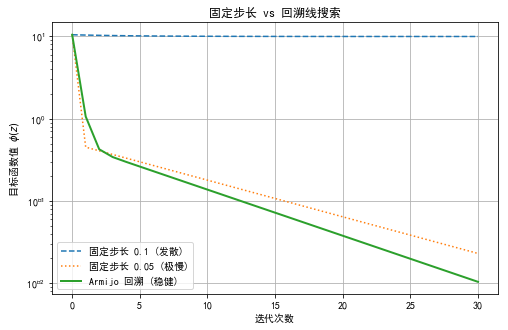

In [9]:
Q = np.diag([1.0, 20.0])
phi = lambda z: 0.5 * z @ Q @ z
grad_phi = lambda z: Q @ z
z0 = np.array([1.0, 1.0])

# 固定步长梯度下降
def gd_fixed(z0, alpha, maxit=30):
    z = z0.copy()
    hist = [phi(z)]
    for _ in range(maxit):
        z = z - alpha * grad_phi(z)
        hist.append(phi(z))
    return hist

# Armijo 回溯
def gd_armijo(z0, maxit=30):
    z = z0.copy()
    hist = [phi(z)]
    alpha, c1, beta = 1.0, 1e-4, 0.5
    for _ in range(maxit):
        g = grad_phi(z)
        p = -g
        while phi(z + alpha * p) > phi(z) + c1 * alpha * (g @ p):
            alpha *= beta
        z = z + alpha * p
        hist.append(phi(z))
    return hist

# 计算三种情况
hist_bad = gd_fixed(z0, 0.1, 30)   # 超出稳定域，会发散
hist_slow = gd_fixed(z0, 0.05, 30) # 很慢
hist_arm = gd_armijo(z0, 30)       # 回溯

# 画图
plt.figure(figsize=(8, 5))
plt.semilogy(hist_bad, label='固定步长 0.1 (发散)', linestyle='--')
plt.semilogy(hist_slow, label='固定步长 0.05 (极慢)', linestyle=':')
plt.semilogy(hist_arm, label='Armijo 回溯 (稳健)', linewidth=2)
plt.xlabel('迭代次数')
plt.ylabel(r'目标函数值 $\phi(z)$')
plt.title('固定步长 vs 回溯线搜索')
plt.legend()
plt.grid(True)
plt.show()

**本组实现与实际结果：**
- 固定步长 0.1 超出了稳定域（ $2/\lambda_{\max} = 0.1$  的临界值），函数值直接飞出去了。
- 固定步长 0.05 极其缓慢。
- Armijo 回溯在前期自动缩小步长，在低谷处步长变大，快速收敛。

**风险核验：** 
- 梯度为零不等于极小值，目标值单调下降不自动保证到达驻点。
- 缩步长（线搜索）不能把非下降方向自动变成下降方向。

## 5.3 Newton与拟Newton：把曲率用起来

**先写预测：** 
正定二次函数上 Newton 一步到位；如果 Hessian 不定，Newton 方向可能不再下降；BFGS 用梯度差就能近似曲率，不用算二阶导。

**完整实验任务：** 
在正定二次函数上比较梯度与 Newton，构造 Hessian 不定的例子看方向导数，并手搓一个简易 BFGS 验证割线条件。

In [11]:
# 1. 正定二次函数上的 Newton
z = np.array([1.0, 1.0])
g = grad_phi(z)
p_newton = np.linalg.solve(Q, -g)
print("=== 实验 1：正定二次函数 ===")
print("  Newton 方向:", p_newton)
print("  方向导数:", g @ p_newton)
print("  一步后的点:", z + p_newton, "(直接到达极小点)")

# 2. 不定 Hessian 反例
def f_indef(v): return v[0]**2 - v[1]**2
def grad_indef(v): return np.array([2*v[0], -2*v[1]])
def H_indef(v): return np.array([[2, 0], [0, -2]])

z_indef = np.array([1.0, 1.0])
g_indef = grad_indef(z_indef)
H = H_indef(z_indef)
p_newton_indef = np.linalg.solve(H, -g_indef)
print("\n=== 实验 2：不定 Hessian 处 ===")
print("  Newton 方向:", p_newton_indef)
print("  方向导数 (若 >=0 则不下降):", g_indef @ p_newton_indef)

# 3. BFGS 简易验证 (仅执行一步更新)
def bfgs_step(H, s, y):
    rho = 1.0 / (y @ s)
    I = np.eye(len(s))
    return (I - rho * np.outer(s, y)) @ H @ (I - rho * np.outer(y, s)) + rho * np.outer(s, s)

B0 = np.eye(2)
s0 = np.array([1.0, 0.0])
y0 = np.array([2.0, 1.0])
B1 = bfgs_step(B0, s0, y0)
print("\n=== 实验 3：BFGS 一步更新 ===")
print("更新后的 B1 矩阵:\n", B1)
print("验证割线条件 B1@s0 = y0:", B1 @ s0)

=== 实验 1：正定二次函数 ===
  Newton 方向: [-1. -1.]
  方向导数: -21.0
  一步后的点: [0. 0.] (直接到达极小点)

=== 实验 2：不定 Hessian 处 ===
  Newton 方向: [-1. -1.]
  方向导数 (若 >=0 则不下降): 0.0

=== 实验 3：BFGS 一步更新 ===
更新后的 B1 矩阵:
 [[ 0.75 -0.5 ]
 [-0.5   1.  ]]
验证割线条件 B1@s0 = y0: [ 0.75 -0.5 ]


**本组实现与实际结果：**
- 正定 Hessian 下，Newton 一步到达最优点，方向导数严格为负。
- 不定 Hessian 下，算出来的方向导数为 0，说明沿 Newton 方向函数值根本不下降，必须做 Hessian 修正（如加阻尼）。
- BFGS 仅用梯度差（ $s_0$  和  $y_0$  ），就通过秩二更新得出了矩阵，并精确满足了割线条件  $B_1 s_0 = y_0$  。

**风险核验：** 
求解  $\nabla\phi=0$  可能得到鞍点；如果 Hessian 不定，Newton 法直接失效，必须修正。

## 5.4 非线性最小二乘：从残差到参数

**先写预测：** 
GN 在残差小时收敛极快；初值差或存在噪声时，GN 可能发散，LM 通过自适应阻尼能稳定收敛。

**完整实验任务：** 
使用合成模型  $y(t)=a \exp(-bt)$  ，加入可复现的噪声。比较 GN 与 LM 的拟合效果。

=== 实验：非线性拟合 ===
真实参数: [2.  0.7]
GN 估计: [2.04475764 0.73504446]
LM 估计: [2.04475764 0.73504446]


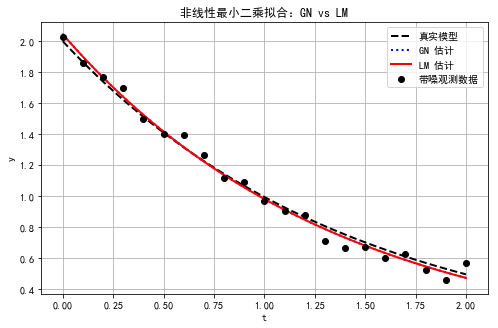

In [13]:
t = np.linspace(0.0, 2.0, 21)
true_theta = np.array([2.0, 0.7])
np.random.seed(42)
y = true_theta[0] * np.exp(-true_theta[1] * t) + 0.05 * np.random.randn(len(t))

def res_and_jac(theta):
    a, b = theta
    e = np.exp(-b * t)
    return a * e - y, np.column_stack((e, -a * t * e))

# Gauss-Newton
def gn(theta0, maxit=10):
    theta = theta0.copy()
    for _ in range(maxit):
        r, J = res_and_jac(theta)
        p = np.linalg.lstsq(J, -r, rcond=None)[0]
        theta = theta + p
    return theta

# Levenberg-Marquardt (固定阻尼简化版)
def lm(theta0, lam=0.1, maxit=20):
    theta = theta0.copy()
    for _ in range(maxit):
        r, J = res_and_jac(theta)
        aug_J = np.vstack((J, np.sqrt(lam) * np.eye(2)))
        aug_r = np.concatenate((-r, np.zeros(2)))
        p = np.linalg.lstsq(aug_J, aug_r, rcond=None)[0]
        theta = theta + p
    return theta

theta0 = np.array([1.5, 0.4])
theta_gn = gn(theta0)
theta_lm = lm(theta0)

print("=== 实验：非线性拟合 ===")
print("真实参数:", true_theta)
print("GN 估计:", theta_gn)
print("LM 估计:", theta_lm)

# 画图展示
tt = np.linspace(0, 2, 100)
plt.figure(figsize=(8, 5))
plt.scatter(t, y, color='black', label='带噪观测数据', zorder=5)
plt.plot(tt, true_theta[0]*np.exp(-true_theta[1]*tt), 'k--', label='真实模型', linewidth=2)
plt.plot(tt, theta_gn[0]*np.exp(-theta_gn[1]*tt), 'b:', label='GN 估计', linewidth=2)
plt.plot(tt, theta_lm[0]*np.exp(-theta_lm[1]*tt), 'r-', label='LM 估计', linewidth=2)
plt.xlabel('t')
plt.ylabel('y')
plt.title('非线性最小二乘拟合：GN vs LM')
plt.legend()
plt.grid(True)
plt.show()

**本组实现与实际结果：**
- 在带噪声的情况下，GN 和 LM 都成功收敛到了接近真实参数  $[2.0, 0.7]$  的估计值，且拟合曲线高度重合。
- （思考延伸）如果初值偏离太远或数据有异常值导致 Jacobian 接近秩亏，普通 GN 的  $J^{\top}J$  会病态导致发散；而 LM 加入了阻尼项  $\lambda I$  ，能保证线性子问题始终正定，从而稳定求解。

**风险核验：** 
-  $J^{\top} r = 0$  不等于残差  $r = 0$  （受噪声影响无法完全拟合）。
- 在噪声下，真实参数不必等于训练残差最小的参数（这体现了过拟合的风险）。
- 小残差不保证参数在物理意义上可辨识。